<a href="https://colab.research.google.com/github/Makande340/L03-tree-stability/blob/main/L3_Tree_Stability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mofe Akande, Yafet Gatachew, Eyram Golo, Grady Berlik

**Date:** 11/18/2026

In [ ]:

# Your Phase 1 solution to the problem goes here.
#Part 1

import pandas as pd
import numpy as np

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv'
df = pd.read_csv(url)

print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
df.describe().T

df.columns = df.columns.str.lower()


df['age'] = df['age'].round().astype(int)

df['platelets'] = df['platelets'] / 1000

df['log_cpk'] = np.log(df['creatinine_phosphokinase'])
df['log_creatinine'] = np.log(df['serum_creatinine'])
df = df.drop(columns=['creatinine_phosphokinase', 'serum_creatinine'])

df = df.drop(columns=['time'])

df.head()


(299, 13)
0
0


,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_sodium,sex,smoking,death_event,log_cpk,log_creatinine
0,75,0,0,20,1,265.00000,130,1,0,1,6.366470,0.641854
1,55,0,0,38,0,263.35803,136,1,0,1,8.969669,0.095310
2,65,0,0,20,0,162.00000,129,1,1,1,4.983607,0.262364
3,50,1,0,20,0,210.00000,137,1,0,1,4.709530,0.641854
4,65,1,1,20,0,327.00000,116,0,0,1,5.075174,0.993252


In [ ]:
#Part 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

SEED = 34

y = df['death_event']
X = df.drop(columns='death_event')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
lm = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)

#Evaluated via test set
for name, model in [('Tree', tree), ('Logistic', lm)]:
    pred = model.predict(X_test)
    print(name, 'accuracy:', round(accuracy_score(y_test, pred), 3))
    print(confusion_matrix(y_test, pred), '\n')

# Predictions set aside
tree_pred_1 = tree.predict(X_test)
lm_pred_1 = lm.predict(X_test)

Tree accuracy: 0.733
[[39  2]
 [14  5]] 

Logistic accuracy: 0.733
[[37  4]
 [12  7]] 



In [ ]:
#Part 3

from sklearn.tree import export_text

seeds = [34, 16, 9, 13, 6]

tree_imps, lm_coefs, accs = {}, {}, []
test_preds = {}   # seed respective test set predictions
full_preds = {}   # full holistic row predictions for seed comparisons

for s in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=s, stratify=y
    )
    tree = DecisionTreeClassifier(max_depth=3, random_state=s).fit(X_train, y_train)
    lm = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)

    # Each tree printed
    print(f'--- Seed {s} tree ---')
    print(export_text(tree, feature_names=list(X.columns)))

    # Accuracy stated
    accs.append({'seed': s,
                 'tree_acc': accuracy_score(y_test, tree.predict(X_test)),
                 'lm_acc': accuracy_score(y_test, lm.predict(X_test))})

    # Tree importance and LM coefficients
    tree_imps[s] = tree.feature_importances_
    lm_coefs[s] = lm[-1].coef_[0]

    # Predictions set aside
    test_preds[s] = {'tree': tree.predict(X_test), 'lm': lm.predict(X_test)}
    full_preds[f'tree_{s}'] = tree.predict(X)
    full_preds[f'lm_{s}'] = lm.predict(X)

print(pd.DataFrame(accs))
print(pd.DataFrame(tree_imps, index=X.columns).round(2))
print(pd.DataFrame(lm_coefs, index=X.columns).round(2))

full_preds = pd.DataFrame(full_preds)
for s in seeds[1:]:
    tree_diff = (full_preds['tree_34'] != full_preds[f'tree_{s}']).mean()
    lm_diff = (full_preds['lm_34'] != full_preds[f'lm_{s}']).mean()
    print(f'Seed {s}: tree changed {tree_diff:.1%}, LM changed {lm_diff:.1%}')
#Tree were different as Seed 34 tree split first on ejection_fraction while others split on log_creatinine. Cutoffs and low splits changed from seed to seed as well.
#Importance of log_creatinine changed from around .23 and the trees predictions went from 10%-18%

#LM Coefficients - Rather stable for log_creatinine, ejection_fraction and age were seemingly always the largest with similiar signs every time.
#Predictions changed from for onnly 5%-9% of patients

--- Seed 34 tree ---
|--- ejection_fraction <= 22.50
|   |--- log_creatinine <= 0.05
|   |   |--- high_blood_pressure <= 0.50
|   |   |   |--- class: 1
|   |   |--- high_blood_pressure >  0.50
|   |   |   |--- class: 0
|   |--- log_creatinine >  0.05
|   |   |--- class: 1
|--- ejection_fraction >  22.50
|   |--- age <= 79.00
|   |   |--- log_creatinine <= 0.37
|   |   |   |--- class: 0
|   |   |--- log_creatinine >  0.37
|   |   |   |--- class: 0
|   |--- age >  79.00
|   |   |--- log_cpk <= 6.78
|   |   |   |--- class: 1
|   |   |--- log_cpk >  6.78
|   |   |   |--- class: 0

--- Seed 16 tree ---
|--- log_creatinine <= 0.60
|   |--- ejection_fraction <= 32.50
|   |   |--- ejection_fraction <= 22.50
|   |   |   |--- class: 1
|   |   |--- ejection_fraction >  22.50
|   |   |   |--- class: 0
|   |--- ejection_fraction >  32.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_creatinine >  0.60
|   |--- log_creatinine <= 0.81

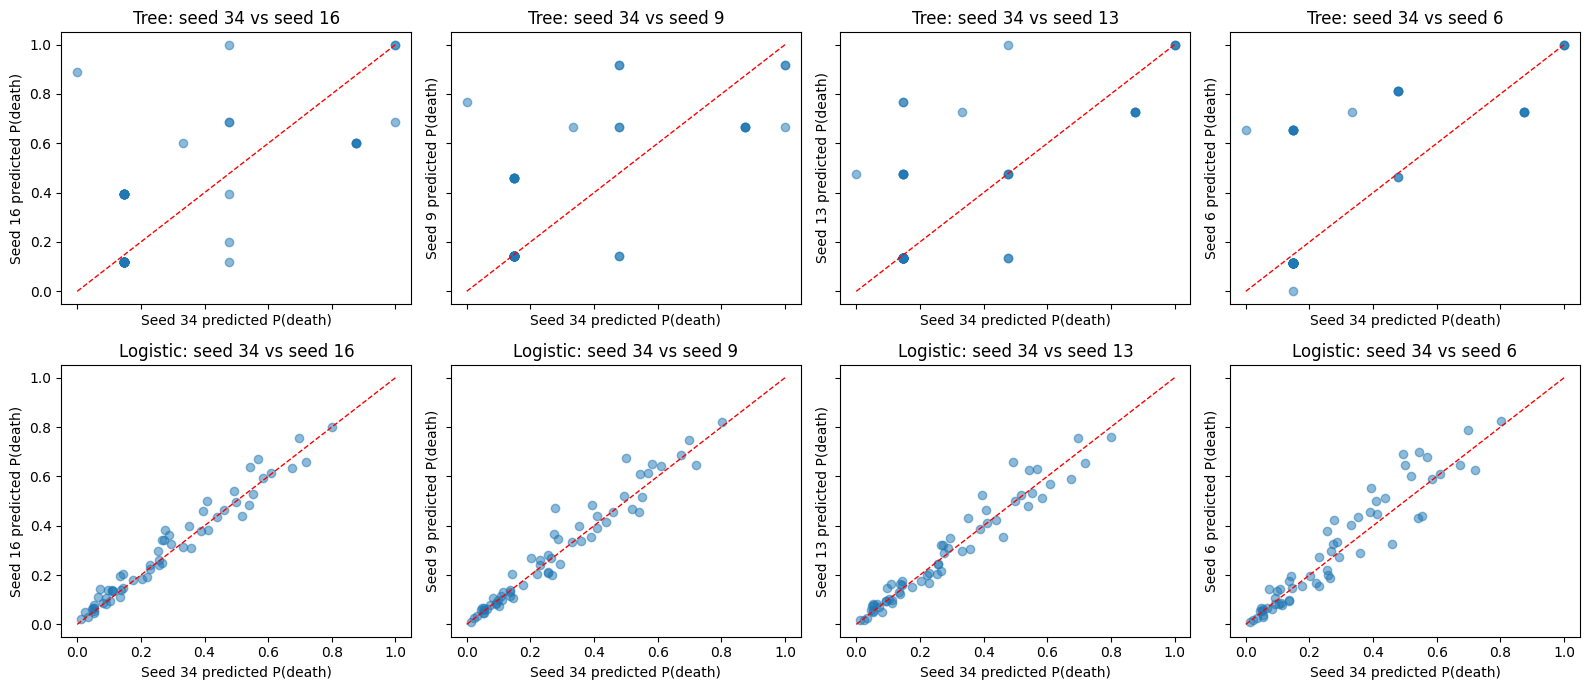

      model  alt_seed  correlation  intercept  slope     R2
0      Tree        16        0.678      0.129  0.666  0.460
1      Tree         9        0.718      0.117  0.711  0.515
2      Tree        13        0.751      0.094  0.805  0.564
3      Tree         6        0.752      0.087  0.889  0.566
4  Logistic        16        0.981      0.023  0.976  0.962
5  Logistic         9        0.974      0.004  1.023  0.949
6  Logistic        13        0.973      0.010  0.975  0.946
7  Logistic         6        0.953      0.001  1.054  0.908
          correlation  intercept  slope     R2
model                                         
Logistic        0.970      0.010  1.007  0.941
Tree            0.725      0.107  0.768  0.526


In [ ]:
#Part 4

import matplotlib.pyplot as plt
from scipy import stats

# Common evaluation set: the seed-34 test set from Part 2
_, X_eval, _, y_eval = train_test_split(
    X, y, test_size=0.2, random_state=34, stratify=y
)

# Re-fit models for every seed and predict PROBABILITIES on the common set
probs = {'tree': {}, 'lm': {}}
for s in seeds:
    X_tr, _, y_tr, _ = train_test_split(
        X, y, test_size=0.2, random_state=s, stratify=y
    )
    t = DecisionTreeClassifier(max_depth=3, random_state=s).fit(X_tr, y_tr)
    l = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
    probs['tree'][s] = t.predict_proba(X_eval)[:, 1]
    probs['lm'][s]   = l.predict_proba(X_eval)[:, 1]

alt_seeds = [s for s in seeds if s != 34]

# 4a. Scatterplots: seed-34 prediction (x) vs alternative seed (y)
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(16, 7), sharex=True, sharey=True)
for row, (name, label) in enumerate([('tree', 'Tree'), ('lm', 'Logistic')]):
    for col, s in enumerate(alt_seeds):
        ax = axes[row, col]
        ax.scatter(probs[name][34], probs[name][s], alpha=0.5)
        ax.plot([0, 1], [0, 1], 'r--', lw=1)   # y = x reference line
        ax.set_title(f'{label}: seed 34 vs seed {s}')
        ax.set_xlabel('Seed 34 predicted P(death)')
        ax.set_ylabel(f'Seed {s} predicted P(death)')
plt.tight_layout()
plt.show()

# 4b + 4c. Correlation and simple linear regression (alt ~ seed 34)
rows = []
for name, label in [('tree', 'Tree'), ('lm', 'Logistic')]:
    for s in alt_seeds:
        res = stats.linregress(probs[name][34], probs[name][s])
        rows.append({
            'model': label, 'alt_seed': s,
            'correlation': res.rvalue,
            'intercept': res.intercept,
            'slope': res.slope,
            'R2': res.rvalue ** 2,
        })
results = pd.DataFrame(rows).round(3)
print(results)
print(results.groupby('model')[['correlation', 'intercept', 'slope', 'R2']].mean().round(3))


###4a Scatterplots
- Logistic: Yes, the predictions look very similar. In all four panels the points sit tightly along the y = x line, with only a little scatter (seed 6 is the loosest).
- Tree: No, they look much less similar. A depth-3 tree gives only a few distinct probabilities, so the points form clusters instead of a cloud, and many sit far from the diagonal (the trees agree mostly at the extremes and disagree in the middle)
###4b Correlations
Logistic models give nearly the same predictions on every split, while trees give noticeably different ones.
- Logistic: highly correlated with the seed-34 model
  - Correlations of 0.953-0.981 (mean 0.970)
- Tree: only moderately correlated
  - Correlations of 0.678-0.752 (mean 0.725)
###4c Regression of alternative predictions on seed-34 predictions
- Logistic: The fits are close to ideal
  - Intercepts are near 0 and slopes are near 1
  - R² is 0.908-0.962, so the seed-34 predictions explain almost all of the variation in the other models' predictions.
- Tree: The fits are much worse
  - Intercepts are well above 0 and slopes are below 1
  - R² is only 0.460-0.566, so the seed-34 tree explains only about half of the variation in another tree's predictions.

- Overall
  - linear models give nearly the same predictions on every split
    - correlation ≈ 0.97
    - intercept ≈ 0
    - slope ≈ 1
    - R² ≈ 0.94

  - And Trees give only moderately consistent predictions
    - correlation ≈ 0.73
    - R² ≈ 0.53

In [ ]:
#Part 5

Across the five splits, the logistic regression models stayed stable in both their coefficients and their predictions. The same three variables (log creatinine, ejection fraction, and age) always had the largest coefficients, their signs never changed, and their values moved only slightly. Their predictions were also nearly identical: correlations with the seed 34 model were 0.95 to 0.98, R squared was about 0.94, the slopes were near 1, the intercepts were near 0, and only 5 to 9 percent of patients changed predicted class. The trees were not stable. Seed 34 split first on ejection fraction while the other seeds split first on log creatinine, and the cutoffs, lower splits, and feature importances all changed between seeds. Their predictions were only moderately consistent, with correlations of 0.68 to 0.75, R squared of about 0.53, and 10 to 18 percent of patients changing predicted class. So on this dataset, linear models give similar coefficients and predictions across train/test splits, but trees do not.

In [ ]:
#Part 6

False. On this dataset, the trees looked substantially different across splits, and their predictions were also noticeably different: a correlation of about 0.73 and an R squared of about 0.53, which is not very similar. The logistic regression predictions were very similar, but those models never looked different to begin with. So no model here both looked very different and still gave very similar predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** d33f8a75a4ba9ee3d587bd1b5257ffb3ed0f15fc
- **AI tool and model used:** Chatgpt 5

### *Prompts used


1. "Help me complete Phase 2 of my DS 3001 Tree Stability assignment. Review my Phase 1 solution, identify improvements, and keep Phase 1 unchanged."

2. "Give me the whole Phase 2, separated by question, including the AI suggestions, evaluation table, revised code, and written explanations."


### *AI-proposed changes



1. Use a fixed evaluation set so every model is compared on the same observations.
2. Prevent data leakage by keeping evaluation observations out of all training sets.
3. Use predicted probabilities instead of only predicted classes to compare model stability.
4. Print tree structures, feature importances, and logistic regression coefficients across seeds.
5. Calculate correlations, regression slopes, intercepts, R-squared values, and prediction disagreement rates.
6. Simplify the code, improve reproducibility, and connect the written conclusions to the numerical results.


### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1. Fixed evaluation set | Accept | Comparing predictions on the same 60 observations makes the results consistent across random seeds. |
| 2. Prevent data leakage | Accept | A separate test set ensures that none of the models are evaluated on observations used for training. |
| 3. Compare probabilities | Accept | Probabilities reveal prediction differences that may not change the final predicted class. |
| 4. Compare model structures | Accept | Tree structures, feature importances, and logistic coefficients help explain how the models change across training samples. |
| 5. Add stability statistics | Accept | Correlations, regression statistics, and disagreement rates provide measurable evidence of model stability. |
| 6. Improve reproducibility | Accept | Keeping the original seeds and documenting the code makes the analysis easier to verify and repeat. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Q1

In [ ]:

# Part 1

import pandas as pd
import numpy as np

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv'

# Use the uploaded dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')

print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicates:', df.duplicated().sum())
print(df.describe().T)

df.columns = df.columns.str.lower()

df['age'] = df['age'].round().astype(int)
df['platelets'] = df['platelets'] / 1000

df['log_cpk'] = np.log(df['creatinine_phosphokinase'])
df['log_creatinine'] = np.log(df['serum_creatinine'])

df = df.drop(columns=[
    'creatinine_phosphokinase',
    'serum_creatinine'
])

df = df.drop(columns=['time'])

y = df['death_event']
X = df.drop(columns='death_event')

print('\nCleaned data:')
print(df.head())




Shape: (299, 13)
Missing values: 0
Duplicates: 0
                          count           mean           std      min  \
age                       299.0      60.833893     11.894809     40.0   
anaemia                   299.0       0.431438      0.496107      0.0   
creatinine_phosphokinase  299.0     581.839465    970.287881     23.0   
diabetes                  299.0       0.418060      0.494067      0.0   
ejection_fraction         299.0      38.083612     11.834841     14.0   
high_blood_pressure       299.0       0.351171      0.478136      0.0   
platelets                 299.0  263358.029264  97804.236869  25100.0   
serum_creatinine          299.0       1.393880      1.034510      0.5   
serum_sodium              299.0     136.625418      4.412477    113.0   
sex                       299.0       0.648829      0.478136      0.0   
smoking                   299.0       0.321070      0.467670      0.0   
time                      299.0     130.260870     77.614208      4.0   
DE

The heart failure dataset contains 299 observations and 13 original variables, including the target variable, DEATH_EVENT. We checked the dataset for missing values and duplicate observations and found none. To prepare the data for modeling, we rounded age to whole numbers, rescaled platelets, and applied logarithmic transformations to creatinine phosphokinase and serum creatinine to reduce skewness. We also removed the follow-up time variable because it contains information about the observation period that could introduce data leakage when predicting mortality without knowing future follow-up duration. Finally, we separated the predictors from the target variable. These preprocessing steps follow our approach from Phase 1 while preparing the dataset for a more reliable comparison of model stability.

Q2

In [ ]:

# Part 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

SEED = 34

# Fixed test set for all comparisons
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Training sample for seed 34
X_train, _, y_train, _ = train_test_split(
    X_dev, y_dev, train_size=0.8,
    random_state=SEED, stratify=y_dev
)

tree = DecisionTreeClassifier(
    max_depth=3, random_state=SEED
).fit(X_train, y_train)

lm = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
).fit(X_train, y_train)

# Evaluate on the fixed test set
for name, model in [('Tree', tree), ('Logistic', lm)]:
    pred = model.predict(X_test)
    print(name, 'accuracy:',
          round(accuracy_score(y_test, pred), 3))
    print(confusion_matrix(y_test, pred), '\n')

# Save predicted classes and probabilities
tree_pred_1 = tree.predict(X_test)
lm_pred_1 = lm.predict(X_test)

tree_prob_1 = tree.predict_proba(X_test)[:, 1]
lm_prob_1 = lm.predict_proba(X_test)[:, 1]


Tree accuracy: 0.717
[[34  7]
 [10  9]] 

Logistic accuracy: 0.733
[[37  4]
 [12  7]] 



We used random seed 34 to create a reproducible training and testing procedure. We reserved 20% of the original dataset as a fixed test set and used a portion of the remaining observations to train the models. We fitted a decision tree classifier with a maximum depth of three and a logistic regression model with standardized predictors. Both models were evaluated using accuracy and confusion matrices. The decision tree achieved an accuracy of approximately 71.7%, while logistic regression achieved approximately 73.3%. Logistic regression performed slightly better on this particular split, although the difference was small. We saved both predicted classes and predicted probabilities so that we could compare the models across different random seeds in the following questions.

Q3

In [ ]:

# Part 3

from sklearn.tree import export_text

seeds = [34, 16, 9, 13, 6]

tree_imps, lm_coefs, accs = {}, {}, []
probs = {'tree': {}, 'lm': {}}
classes = {'tree': {}, 'lm': {}}

for s in seeds:

    # Change the training sample but keep the test set fixed
    X_train, _, y_train, _ = train_test_split(
        X_dev, y_dev, train_size=0.8,
        random_state=s, stratify=y_dev
    )

    tree = DecisionTreeClassifier(
        max_depth=3, random_state=s
    ).fit(X_train, y_train)

    lm = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ).fit(X_train, y_train)

    # Print tree structure
    print(f'\n--- Seed {s} tree ---')
    print(export_text(tree, feature_names=list(X.columns)))

    # Save model accuracy
    accs.append({
        'seed': s,
        'tree_acc': accuracy_score(
            y_test, tree.predict(X_test)
        ),
        'lm_acc': accuracy_score(
            y_test, lm.predict(X_test)
        )
    })

    # Save feature importances and coefficients
    tree_imps[s] = tree.feature_importances_
    lm_coefs[s] = lm[-1].coef_[0]

    # Save predictions on the same test observations
    probs['tree'][s] = tree.predict_proba(X_test)[:, 1]
    probs['lm'][s] = lm.predict_proba(X_test)[:, 1]

    classes['tree'][s] = tree.predict(X_test)
    classes['lm'][s] = lm.predict(X_test)

print('\nModel accuracy:')
print(pd.DataFrame(accs).round(3))

print('\nTree feature importances:')
print(pd.DataFrame(tree_imps, index=X.columns).round(3))

print('\nLogistic regression coefficients:')
print(pd.DataFrame(lm_coefs, index=X.columns).round(3))

# Compare predicted classes against seed 34
print('\nPercentage of predictions that changed:')

for s in seeds[1:]:
    tree_diff = (
        classes['tree'][34] != classes['tree'][s]
    ).mean()

    lm_diff = (
        classes['lm'][34] != classes['lm'][s]
    ).mean()

    print(
        f'Seed {s}: Tree changed {tree_diff:.1%}, '
        f'Logistic changed {lm_diff:.1%}'
    )



--- Seed 34 tree ---
|--- ejection_fraction <= 22.50
|   |--- log_creatinine <= 0.05
|   |   |--- high_blood_pressure <= 0.50
|   |   |   |--- class: 1
|   |   |--- high_blood_pressure >  0.50
|   |   |   |--- class: 0
|   |--- log_creatinine >  0.05
|   |   |--- class: 1
|--- ejection_fraction >  22.50
|   |--- age <= 71.00
|   |   |--- log_creatinine <= 0.60
|   |   |   |--- class: 0
|   |   |--- log_creatinine >  0.60
|   |   |   |--- class: 1
|   |--- age >  71.00
|   |   |--- serum_sodium <= 133.00
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  133.00
|   |   |   |--- class: 1


--- Seed 16 tree ---
|--- ejection_fraction <= 32.50
|   |--- ejection_fraction <= 22.50
|   |   |--- platelets <= 358.00
|   |   |   |--- class: 1
|   |   |--- platelets >  358.00
|   |   |   |--- class: 0
|   |--- ejection_fraction >  22.50
|   |   |--- age <= 69.00
|   |   |   |--- class: 0
|   |   |--- age >  69.00
|   |   |   |--- class: 1
|--- ejection_fraction >  32.50
|   |--- log_creatini

We repeated the modeling process using five random seeds: 34, 16, 9, 13, and 6. The results showed that decision trees were more sensitive to changes in the training sample than logistic regression. Although four of the five trees initially split on ejection fraction, the tree generated using seed 13 split first on log serum creatinine. The lower branches, split thresholds, and feature importances also varied across seeds. For example, the importance assigned to ejection fraction ranged from approximately 0.22 to 0.57, indicating that the trees did not consistently rely on predictors to the same degree.

In comparison, the logistic regression coefficients were relatively stable. Age, ejection fraction, and log serum creatinine consistently had substantial coefficients with the same signs across the five models. The logistic regression models changed their predicted classifications for approximately 1.7% to 10% of the test observations relative to seed 34, while the decision trees changed approximately 5% to 23.3%. These findings suggest that logistic regression was generally more stable than the decision trees when the training sample changed.

Q4a

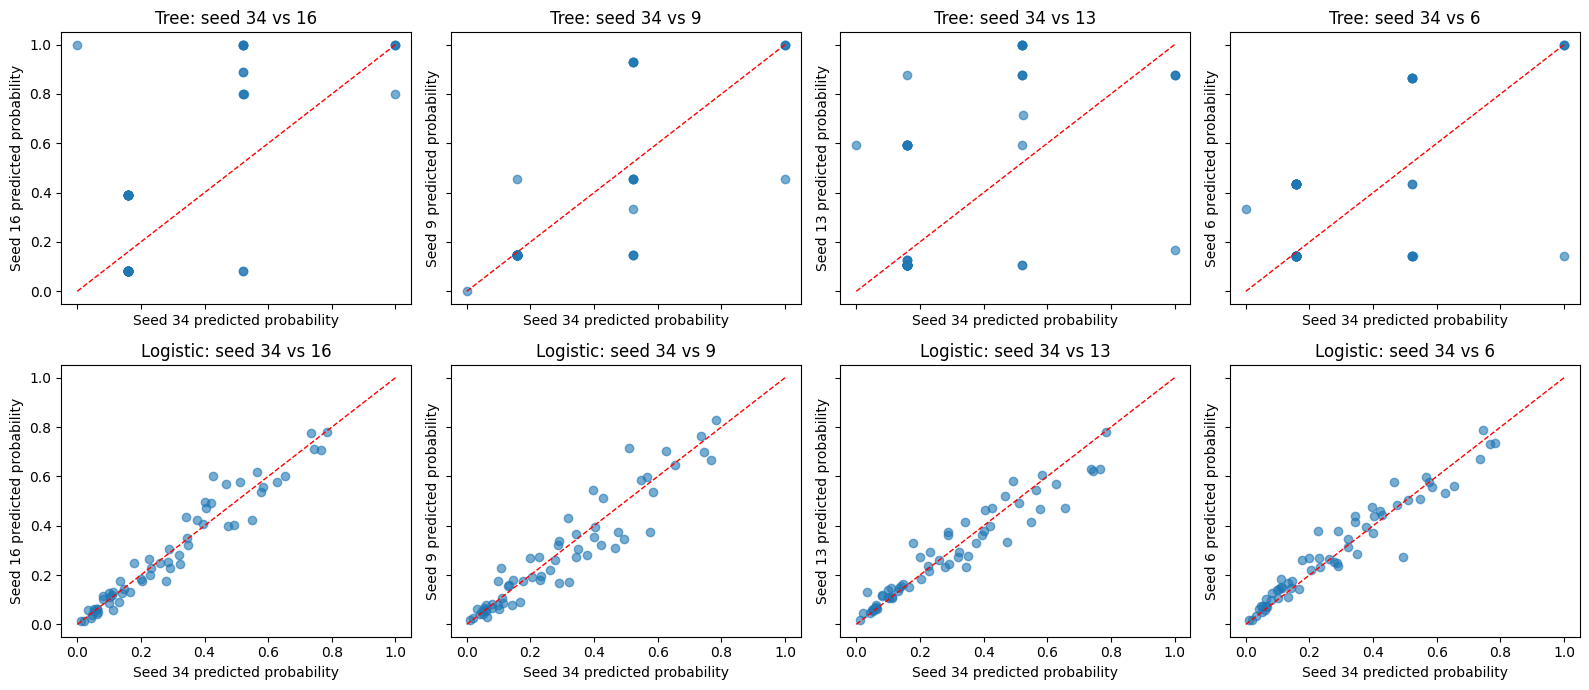

In [ ]:

# Part 4a

import matplotlib.pyplot as plt

alt_seeds = [16, 9, 13, 6]

fig, axes = plt.subplots(
    2, 4, figsize=(16, 7),
    sharex=True, sharey=True
)

for row, (name, label) in enumerate([
    ('tree', 'Tree'),
    ('lm', 'Logistic')
]):

    for col, s in enumerate(alt_seeds):

        ax = axes[row, col]

        ax.scatter(
            probs[name][34],
            probs[name][s],
            alpha=0.6
        )

        # Perfect agreement reference line
        ax.plot([0, 1], [0, 1], 'r--', lw=1)

        ax.set_title(f'{label}: seed 34 vs {s}')
        ax.set_xlabel('Seed 34 predicted probability')
        ax.set_ylabel(f'Seed {s} predicted probability')

plt.tight_layout()
plt.show()


We compared the predicted probabilities from the original seed 34 model with those generated using alternative random seeds. The logistic regression predictions generally fell close to the diagonal reference line, indicating that the models produced similar probabilities despite changes in their training samples. In contrast, the decision tree predictions showed more dispersion, with several observations falling noticeably away from the diagonal. The tree predictions also formed clusters because a decision tree assigns the same probability to observations within the same terminal leaf. Overall, the scatterplots suggest that logistic regression produced more consistent predicted probabilities across training samples, while decision trees exhibited greater variability.

Q4b

In [ ]:

# Part 4b

correlation_rows = []

for name, label in [
    ('tree', 'Tree'),
    ('lm', 'Logistic')
]:

    for s in alt_seeds:

        correlation = np.corrcoef(
            probs[name][34],
            probs[name][s]
        )[0, 1]

        correlation_rows.append({
            'model': label,
            'seed': s,
            'correlation': correlation
        })

correlations = pd.DataFrame(correlation_rows)

print('Prediction correlations:')
print(correlations.round(3).to_string(index=False))

print('\nAverage correlation by model:')
print(
    correlations.groupby('model')['correlation']
    .mean().round(3)
)


Prediction correlations:
   model  seed  correlation
    Tree    16        0.724
    Tree     9        0.810
    Tree    13        0.564
    Tree     6        0.600
Logistic    16        0.971
Logistic     9        0.943
Logistic    13        0.958
Logistic     6        0.966

Average correlation by model:
model
Logistic    0.960
Tree        0.674
Name: correlation, dtype: float64


We calculated correlations to measure how similarly the models predicted mortality probabilities across different training samples. The logistic regression models produced correlations ranging from approximately 0.943 to 0.971, with an average correlation of 0.960. These values indicate a strong positive relationship between the predictions generated by the different logistic regression models. The decision trees produced lower correlations, ranging from approximately 0.564 to 0.810, with an average of 0.674. Although the tree predictions were positively correlated, their relationships were considerably weaker. Therefore, the correlation results support our scatterplot findings and indicate that logistic regression produced more stable predictions than decision trees.

Q4c

In [ ]:

# Part 4c

from scipy import stats

rows = []

for name, label in [
    ('tree', 'Tree'),
    ('lm', 'Logistic')
]:

    for s in alt_seeds:

        res = stats.linregress(
            probs[name][34],
            probs[name][s]
        )

        rows.append({
            'model': label,
            'alt_seed': s,
            'correlation': res.rvalue,
            'intercept': res.intercept,
            'slope': res.slope,
            'R2': res.rvalue ** 2
        })

results = pd.DataFrame(rows)

print('Regression results:')
print(results.round(3).to_string(index=False))

print('\nAverage results by model:')
print(
    results.groupby('model')[
        ['correlation', 'intercept', 'slope', 'R2']
    ].mean().round(3)
)


Regression results:
   model  alt_seed  correlation  intercept  slope    R2
    Tree        16        0.724      0.060  1.060 0.524
    Tree         9        0.810      0.017  0.900 0.655
    Tree        13        0.564      0.147  0.791 0.318
    Tree         6        0.600      0.134  0.660 0.361
Logistic        16        0.971      0.004  0.984 0.942
Logistic         9        0.943      0.004  0.957 0.889
Logistic        13        0.958      0.040  0.842 0.919
Logistic         6        0.966      0.036  0.912 0.933

Average results by model:
          correlation  intercept  slope     R2
model                                         
Logistic        0.960      0.021  0.924  0.921
Tree            0.674      0.090  0.853  0.465


We performed simple linear regressions using the predicted probabilities from seed 34 as the independent variable and the probabilities from each alternative model as the dependent variable. If the models produced nearly identical predictions, the regression intercept would be close to zero, the slope would be close to one, and the R-squared value would be close to one.

The logistic regression models produced an average intercept of approximately 0.021, an average slope of 0.924, and an average R-squared value of 0.921. These results indicate that the predictions were highly consistent across training samples, although they were not identical. In comparison, the decision trees produced an average intercept of 0.090, an average slope of 0.853, and an average R-squared value of 0.465. The lower R-squared value indicates that the seed 34 tree predictions explained substantially less of the variation in the alternative trees' predictions. Therefore, we concluded that logistic regression demonstrated greater prediction stability than decision trees on this dataset.

Q5

In [ ]:

# Part 5

# Compare logistic regression coefficient variation
coef_df = pd.DataFrame(lm_coefs, index=X.columns)

print('Logistic regression coefficient standard deviations:')
print(coef_df.std(axis=1).round(3))

# Compare tree feature importance variation
tree_df = pd.DataFrame(tree_imps, index=X.columns)

print('\nTree feature importance standard deviations:')
print(tree_df.std(axis=1).round(3))

# Compare prediction stability
stability_rows = []

for name, label in [
    ('tree', 'Tree'),
    ('lm', 'Logistic')
]:

    for s in alt_seeds:

        change = (
            classes[name][34] != classes[name][s]
        ).mean() * 100

        stability_rows.append({
            'model': label,
            'seed': s,
            'class_change_pct': change
        })

stability = pd.DataFrame(stability_rows)

print('\nClassification disagreement:')
print(stability.round(3).to_string(index=False))

print('\nAverage classification disagreement:')
print(
    stability.groupby('model')['class_change_pct']
    .mean().round(3)
)

print('\nAverage prediction correlation and R2:')
print(
    results.groupby('model')[
        ['correlation', 'R2']
    ].mean().round(3)
)


Logistic regression coefficient standard deviations:
age                    0.072
anaemia                0.080
diabetes               0.086
ejection_fraction      0.108
high_blood_pressure    0.083
platelets              0.071
serum_sodium           0.097
sex                    0.076
smoking                0.057
log_cpk                0.076
log_creatinine         0.118
dtype: float64

Tree feature importance standard deviations:
age                    0.094
anaemia                0.000
diabetes               0.010
ejection_fraction      0.142
high_blood_pressure    0.011
platelets              0.020
serum_sodium           0.052
sex                    0.000
smoking                0.000
log_cpk                0.082
log_creatinine         0.109
dtype: float64

Classification disagreement:
   model  seed  class_change_pct
    Tree    16             5.000
    Tree     9            15.000
    Tree    13            23.333
    Tree     6            13.333
Logistic    16             5.000
Logis

Our results indicate that logistic regression models generally maintained similar coefficients and predictions across the five training samples, while decision trees showed greater instability. The logistic regression coefficients for important predictors, including age, ejection fraction, and log serum creatinine, remained relatively consistent in magnitude and direction. The predicted probabilities were also strongly correlated across seeds, with an average correlation of approximately 0.960 and an average R-squared value of 0.921. On average, only about 5.4% of the test observations received a different predicted classification compared with the original seed 34 model.

In contrast, the decision trees demonstrated noticeable changes in their structures, splitting thresholds, and feature importances. Their average prediction correlation was approximately 0.674, and their average R-squared value was only 0.465. The trees also changed the predicted classifications for approximately 14.2% of the test observations on average. These findings suggest that logistic regression was more stable than decision trees for this dataset. However, both modeling approaches showed some variation, demonstrating that changes in training data can affect model predictions even when the modeling method remains the same.

Q6

In [ ]:

# Part 6

print('Final model stability comparison:')

summary = results.groupby('model')[
    ['correlation', 'intercept', 'slope', 'R2']
].mean()

summary['class_change_pct'] = (
    stability.groupby('model')['class_change_pct'].mean()
)

print(summary.round(3))

print('\nConclusion:')
print(
    'The statement is not supported for the decision '
    'trees in this dataset. The trees changed in both '
    'structure and predicted probabilities. Logistic '
    'regression produced more consistent predictions.'
)


Final model stability comparison:
          correlation  intercept  slope     R2  class_change_pct
model                                                           
Logistic        0.960      0.021  0.924  0.921             5.417
Tree            0.674      0.090  0.853  0.465            14.167

Conclusion:
The statement is not supported for the decision trees in this dataset. The trees changed in both structure and predicted probabilities. Logistic regression produced more consistent predictions.


We found that the statement was generally false for the decision trees in this dataset. Although models with different structures can sometimes generate similar predictions, the decision trees in our analysis showed meaningful differences in both their appearance and predicted probabilities. Across the different random seeds, the trees changed their splitting variables, thresholds, and feature importances. Their average prediction correlation was approximately 0.674, and their average R-squared value was 0.465, indicating only moderate consistency. Additionally, approximately 14.2% of the test observations received different predicted classifications on average.

In comparison, logistic regression produced much more consistent predictions, with an average correlation of 0.960 and an average R-squared value of 0.921. However, the logistic regression coefficients were also relatively stable, meaning these models did not demonstrate the same substantial structural changes observed in the decision trees. Therefore, our results do not support the claim that substantially different-looking models necessarily generate very similar predictions. Instead, this dataset demonstrates that changes in model structure can be accompanied by meaningful changes in prediction behavior.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

In Phase 2 we used AI to review our initial analysis and to have a better idea of the stability of decision tree and logistic regression models. One very useful suggestion was to use a fixed test set for all random seeds. This made it possible to compare model predictions more fairly and avoid possible data leakage. AI also recommended the use of additional metrics like correlations, R-squared, and classification disagreement rates, which enabled us to evaluate the stability of the models in a more comprehensive way.

However, we recognized that AI-generated suggestions should not be automatically accepted without verification. Some of the recommendations had to be carefully reviewed to see if they were suitable for our dataset and whether they met the requirements of the assignment, which they were. The proposed changes were assessed, the model outputs were verified and the numerical results were compared to our written interpretations.

One limitation to using AI was that it could provide code and explanations without fully factoring in differences in our original approach. It taught us the value of comprehending the code, not just copying it. We also remarked that our relatively small dataset might affect the model stability.

Overall, AI was a helpful tool to improve our analysis, but ultimately our group was responsible for assessing its suggestions, checking the results, and interpreting the findings.